# Week 6 · Topic 4 — Apply, Lambda and Finishing Up

**Box we are building: STORE + PROCESS, the whole job**

A `lambda` is a `def` you don't bother naming, for a one-line function you are
only going to use once — usually right inside `.apply()`.

> **Already know this?** Skip to the *Topic 4 Challenge*.

---
## 1. `.apply()` runs a function on every value in a column

Start with a normal function, the way Week 3 taught it.

In [2]:
import pandas as pd

servers = pd.read_csv("servers.csv")
servers["percent"] = (servers["used"] / servers["total"]) * 100

def classify(percent):
    if percent >= 100:
        return "OVER LIMIT"
    elif percent >= 90:
        return "WARNING"
    else:
        return "OK"

servers["status"] = servers["percent"].apply(classify)
print(servers)

  hostname region  used  total  percent      status
0   srv-01   east    87    100     87.0          OK
1   srv-02   east    45    100     45.0          OK
2   srv-03   west   120    100    120.0  OVER LIMIT
3   srv-04   west    93    100     93.0     WARNING
4   srv-05  north   101    100    101.0  OVER LIMIT
5   srv-06   east    60    100     60.0          OK
6   srv-07   west    30    100     30.0          OK
7   srv-08  north   110    100    110.0  OVER LIMIT
8   srv-09   east    95    100     95.0     WARNING
9   srv-10  north    55    100     55.0          OK


### Your turn
Write your own single-argument function and `.apply()` it to the `used` column.

In [5]:
# your code here

servers["used"] = servers["percent"].apply(classify)
print(servers)

  hostname region        used       total  percent      status
0   srv-01   east          OK          OK     87.0          OK
1   srv-02   east          OK          OK     45.0          OK
2   srv-03   west  OVER LIMIT  OVER LIMIT    120.0  OVER LIMIT
3   srv-04   west     WARNING     WARNING     93.0     WARNING
4   srv-05  north  OVER LIMIT  OVER LIMIT    101.0  OVER LIMIT
5   srv-06   east          OK          OK     60.0          OK
6   srv-07   west          OK          OK     30.0          OK
7   srv-08  north  OVER LIMIT  OVER LIMIT    110.0  OVER LIMIT
8   srv-09   east     WARNING     WARNING     95.0     WARNING
9   srv-10  north          OK          OK     55.0          OK


---
## 2. `lambda` - the same idea, written inline

`lambda parameters: expression` — that IS the whole function. Only one
expression allowed — no `if`/`elif`/`else` statements, no loops.

In [6]:
double = lambda x: x * 2
print(double(21))     # 42 - same as def double(x): return x * 2

42


```
def classify(p):                    lambda p: (
    if p >= 100:                        "OVER LIMIT" if p >= 100
        return "OVER LIMIT"             else "WARNING" if p >= 90
    elif p >= 90:                       else "OK"
        return "WARNING"             )
    else:
        return "OK"

same logic, same result - a block of statements vs one expression
```

### Your turn
Write `classify` as a lambda with a chained conditional, and check it gives the same result as the `def` version for every row.

In [12]:
# your code here


lambda p: "over limit" if p >= 100 else "warning" if p >= 90 else "ok"

servers["status"] = servers["percent"].apply(lambda p: "over limit" if p >= 100 else "warning" if p >= 90 else "ok")
print(servers)



  hostname region  used  total  percent      status
0   srv-01   east    87    100     87.0          ok
1   srv-02   east    45    100     45.0          ok
2   srv-03   west   120    100    120.0  over limit
3   srv-04   west    93    100     93.0     warning
4   srv-05  north   101    100    101.0  over limit
5   srv-06   east    60    100     60.0          ok
6   srv-07   west    30    100     30.0          ok
7   srv-08  north   110    100    110.0  over limit
8   srv-09   east    95    100     95.0     warning
9   srv-10  north    55    100     55.0          ok


---
## 3. `.apply()` with a lambda, and `sort_values(key=...)`

lambda earns its place exactly here — a function small enough to write inline,
used exactly once, right where it is needed.

In [14]:
servers["status"] = servers["percent"].apply(
    lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK"
)
print(servers.sort_values("hostname", key=lambda col: col.str.lower()))

  hostname region  used  total  percent      status
0   srv-01   east    87    100     87.0          OK
1   srv-02   east    45    100     45.0          OK
2   srv-03   west   120    100    120.0  OVER LIMIT
3   srv-04   west    93    100     93.0     WARNING
4   srv-05  north   101    100    101.0  OVER LIMIT
5   srv-06   east    60    100     60.0          OK
6   srv-07   west    30    100     30.0          OK
7   srv-08  north   110    100    110.0  OVER LIMIT
8   srv-09   east    95    100     95.0     WARNING
9   srv-10  north    55    100     55.0          OK


### Your turn
Use `.apply()` with a lambda to add a column `region_upper` — the `region` column, in capitals.

In [9]:
# your code here

servers["region_upper"] = servers["region"].str.upper()
print(servers)

  hostname region        used       total  percent      status region_upper
0   srv-01   east          OK          OK     87.0          OK         EAST
1   srv-02   east          OK          OK     45.0          OK         EAST
2   srv-03   west  OVER LIMIT  OVER LIMIT    120.0  OVER LIMIT         WEST
3   srv-04   west     WARNING     WARNING     93.0     WARNING         WEST
4   srv-05  north  OVER LIMIT  OVER LIMIT    101.0  OVER LIMIT        NORTH
5   srv-06   east          OK          OK     60.0          OK         EAST
6   srv-07   west          OK          OK     30.0          OK         WEST
7   srv-08  north  OVER LIMIT  OVER LIMIT    110.0  OVER LIMIT        NORTH
8   srv-09   east     WARNING     WARNING     95.0     WARNING         EAST
9   srv-10  north          OK          OK     55.0          OK        NORTH


---
## 4. Summarising, saving, and a first chart

`describe()` for a quick overview, `.to_csv()` to save, and one chart — straight
off a DataFrame. In a notebook, calling `.plot()` shows the chart inline.

            used  total    percent
count   10.00000   10.0   10.00000
mean    79.60000  100.0   79.60000
std     30.05994    0.0   30.05994
min     30.00000  100.0   30.00000
25%     56.25000  100.0   56.25000
50%     90.00000  100.0   90.00000
75%     99.50000  100.0   99.50000
max    120.00000  100.0  120.00000


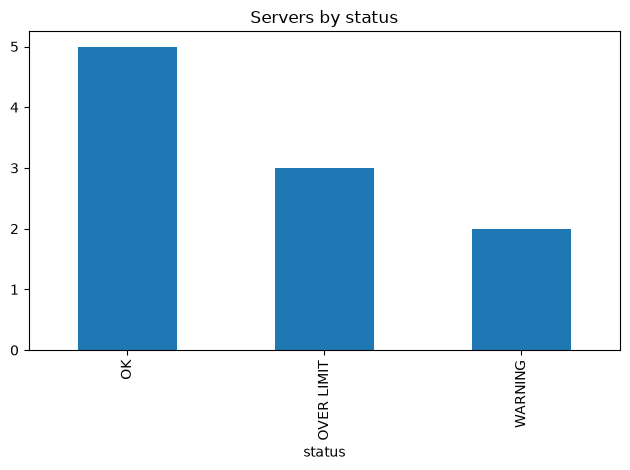

In [3]:
import matplotlib.pyplot as plt

print(servers.describe())

servers.to_csv("servers_report.csv", index=False)

servers["status"].value_counts().plot(kind="bar", title="Servers by status")
plt.tight_layout()
plt.show()

### Your turn
Make a bar chart of servers per region instead of per status.

         percent
count   10.00000
mean    79.60000
std     30.05994
min     30.00000
25%     56.25000
50%     90.00000
75%     99.50000
max    120.00000


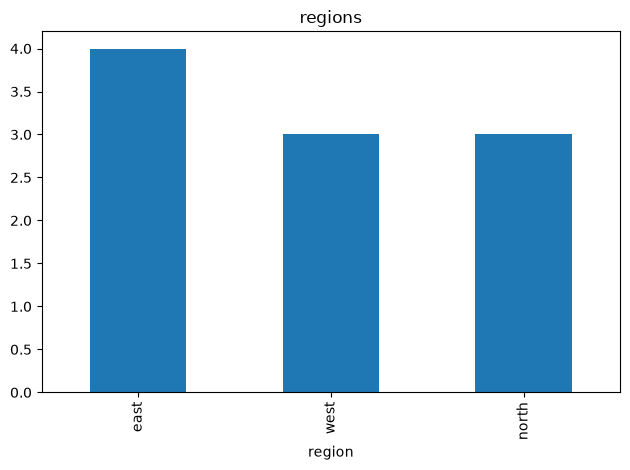

In [10]:
# your code here

import matplotlib.pyplot as plt

print(servers.describe())

servers.to_csv("servers_report.csv", index=False)

servers["region"].value_counts().plot(kind="bar", title="regions")
plt.tight_layout()
plt.show()

---
## Topic 4 Challenge

Load `servers.csv`, add `percent` and `status` (via `.apply()` with a lambda),
save the result to a new CSV, and produce one bar chart of the status counts.

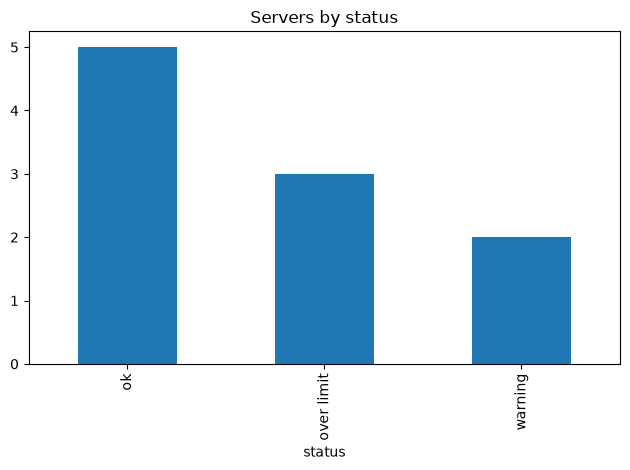

In [11]:
# your code here

import pandas as pd
import matplotlib.pyplot as plt

servers = pd.read_csv("servers.csv")
servers["percent"] = (servers["used"] / servers["total"]) * 100
servers["status"] = servers["percent"].apply(
    lambda p: "over limit" if p >= 100 else "warning" if p >= 90 else "ok"
)

servers.to_csv("servers_report.csv", index=False)

servers["status"].value_counts().plot(kind="bar", title="Servers by status")
plt.tight_layout()
plt.show()



---
## Same idea, three fields

| Field | Looks like |
|---|---|
| **AI / Data Science** | `df["clean_text"] = df["text"].apply(lambda t: t.strip().lower())` |
| **Cyber Security** | `df["flag"] = df["failed"].apply(lambda n: n >= 3)` |
| **IT** | `df.sort_values("hostname", key=lambda c: c.str.lower())` |

---
## Common mistakes

| Mistake | What you see | Fix |
|---|---|---|
| a lambda with an `if` statement (not an expression) | `SyntaxError` | lambda only allows one expression — use chained `if/else`, or write a `def` |
| reusing the same lambda logic in three places | works, but repeats the logic three times | that is the sign you wanted a named function, not a lambda |
| forgetting `.apply()` and just writing `column.classify()` | `AttributeError` | `.apply(function)` runs your function on every value — the function itself is not a method on the column |
| calling `.plot()` in a plain script and seeing nothing | no chart appears | add `plt.show()` (script) — a notebook shows it automatically |

## Go deeper

`examples/01_apply_and_lambda.py` — apply, lambda syntax, chained conditionals, sort key
`examples/02_summarizing_saving_and_charting.py` — describe, to_csv, a first chart

---
## Recap

| You can now | Using |
|---|---|
| apply a function to a whole column | `column.apply(function)` |
| write a small inline function | `lambda x: expression` |
| choose lambda vs a named function | one-line, used once → lambda; reused or complex → `def` |
| get a quick overview | `.describe()` |
| save a result | `.to_csv(path, index=False)` |
| chart straight from a DataFrame | `.plot(kind=...)` |

**You now have all of CW1's toolkit.** Your mini-project this week closes it out.